# ¿Por qué gana el ensemble?

## Anatomía del campeón AE+CRGN+phys y quién aporta cada detección en el parque C

*Mantenimiento Predictivo para Aerogeneradores Offshore con Restricciones Ambientales. Trabajo de
Fin de Máster. Cuarto de los ocho notebooks y segundo de los cuatro de explicabilidad.*

## Resumen

El mejor resultado del trabajo en el parque C no es un modelo sino una **fusión de tres
detectores** que miran la turbina de tres maneras distintas. Un autoencoder que reconstruye el
estado (AE), una red contrastiva de grafo que aprende relaciones entre sensores (CRGN) y un score
*sin modelo* que vigila la coherencia de pares de sensores físicamente redundantes
(phys95maxrate). Fusionados a nivel de score, con z-normalización y un combinador **sin pesos que
ajustar**, alcanzan CARE-CV 0.7694 ± 0.007 (5 semillas), superando a la mejor pareja (AE+CRGN,
0.7452) en las cinco semillas, comparadas una a una.

Este notebook analiza esa fusión. Cuantifica el papel de cada miembro con valores de Shapley
exactos, que con 3 jugadores no hay que aproximar, dibuja el mapa de cobertura detector a evento, y
examina las detecciones que **solo existen gracias a la fusión**. El caso principal es el evento 15,
invisible para el autoencoder y para el mejor modelo individual del trabajo (notebook 1), pero cuya
física de coherencia se rompe ~17 días antes del final de la ventana de fallo, de modo que la fusión
lo alarma con 402 horas de antelación. También documenta el coste y los límites, qué evento empeora
al fusionar, por qué el combinador AOM preserva antelaciones que la media diluye, y por qué añadir
un cuarto miembro ya no mejora la métrica.

## 0. Preparación y verificación

Como en el notebook 1, aquí no se reentrena nada. El *gate* de entrada exige que la réplica
reproduzca el CARE-CV de esta semilla, **0.7634**, que es
`fuse_mc_champ_fixcal_c.json` bajo la calibración CUSUM orden-preservante.

In [1]:
# Preparacion del entorno comun a los 4 notebooks XAI
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (str(ROOT), str(ROOT / "scripts")):
    if p not in sys.path:
        sys.path.insert(0, p)
warnings.filterwarnings("ignore")

# ipykernel OutStream no tiene .buffer: evita que el guard utf-8 de los scripts del repo
# (if sys.stdout.encoding != "utf-8": sys.stdout = io.TextIOWrapper(sys.stdout.buffer, ...))
# intente envolverlo al importarlos.
for _s in (sys.stdout, sys.stderr):
    try:
        if getattr(_s, "encoding", None) != "utf-8":
            _s.encoding = "utf-8"
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.xai import (load_ae, load_ae_events, load_meta, load_scores, load_trajdev,
                     load_trajdev_events, trajdev_channel_z)
from src.xai.loaders import DEVICE, ae_scores, trajdev_forecast_errors, trajdev_score
from src.xai.cusum import cusum_series, first_alarm, h_sweep_best, official_cusum
from src.xai import plots as xp
from src.xai.attrib import (ae_integrated_gradients, ae_residual_sensor, occlusion_per_channel,
                            residual_train_stats, trajdev_counterfactual,
                            trajdev_integrated_gradients)
from src.care_official.adapter import OfficialCAREAdapter

xp.set_style()
np.random.seed(42); torch.manual_seed(42)
print(f"ROOT: {ROOT}")
print(f"dispositivo: {DEVICE} | torch {torch.__version__}")

ROOT: .
dispositivo: cuda | torch 2.10.0+cu128


In [2]:
# Los calculos pesados se cachean en results/xai_cache/nb2/
CACHE = ROOT / "results" / "xai_cache" / "nb2"
CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, fn):
    """np.savez de dict de arrays; si existe, carga sin recomputar."""
    p = CACHE / f"{name}.npz"
    if p.exists():
        z = np.load(p, allow_pickle=True)
        return {k: z[k] for k in z.files}
    out = fn()
    np.savez_compressed(p, **out)
    return out

print(f"cache: {CACHE}")

cache: .\results\xai_cache\nb2


In [3]:
from src.fusion import combiners as FC
import run_model
from sweep_timeaddm_scoring import ReplayScorer

FARM = "C"
meta = load_meta(FARM)
eids = list(meta.keys())
adapter = OfficialCAREAdapter(raw_path="data/raw/CARE_To_Compare", farm=FARM, window_size=27)
MIEMBROS = ("ae", "crgn", "phys95maxrate")
raw = {d: load_scores(FARM, d) for d in MIEMBROS}
print({d: f"train {len(t):,} | {len(ev)} eventos" for d, (t, ev) in raw.items()})

{'ae': 'train 1,118,704 | 58 eventos', 'crgn': 'train 28,538 | 58 eventos', 'phys95maxrate': 'train 28,538 | 58 eventos'}


In [4]:
# replica EXACTA de la fusion
def zparts(dets):
    n_big = max(len(raw[d][0]) for d in dets)
    tr, ev = {}, {}
    for d in dets:
        t, e = raw[d]
        trs = t if len(t) >= n_big else np.repeat(t, -(-n_big // len(t)))[:n_big]
        st = FC.NORMALIZERS["zscore"][0](t)
        tr[d] = FC.NORMALIZERS["zscore"][1](trs, st)
        ev[d] = {k: FC.NORMALIZERS["zscore"][1](v, st) for k, v in e.items()}
    return tr, ev

def fusionar(dets, comb="aom"):
    tr, ev = zparts(dets)
    if len(dets) == 1:
        f = lambda zs: zs[0]
    elif comb == "aom":
        f = lambda zs: FC.combine_aom(zs, n_buckets=2)
    elif comb == "avg":
        f = lambda zs: FC.combine_average(zs, [1.0 / len(dets)] * len(dets))
    elif comb == "max":
        f = lambda zs: FC.combine_maximum(zs)
    tr_f = f([tr[d] for d in dets])
    ev_f = {e: f([ev[d][e] for d in dets]) for e in eids}
    return tr_f, ev_f

def care_cv(tr_f, ev_f):
    slim = [{"event_id": e, "event_label": meta[e]["event_label"], "asset_id": meta[e]["asset_id"],
             "labels": meta[e]["labels"], "window_timestamps": meta[e]["window_timestamps"],
             "windows": np.empty(0)} for e in eids]
    res = run_model.evaluate(ReplayScorer([tr_f] + [ev_f[e] for e in eids]),
                             np.empty(0), slim, adapter, 42)
    return res["cv"]["care"]

def _gate():
    tr_f, ev_f = fusionar(MIEMBROS, "aom")
    return {"care": np.array([care_cv(tr_f, ev_f)])}

cv_champ = float(cached("gate_care_champ", _gate)["care"][0])
assert abs(cv_champ - 0.7634) < 2e-3, f"replica no reproduce el campeon s42 post-fix: {cv_champ:.4f}"
print(f"GATE OK — replica del campeon (zscore+aom): CARE-CV {cv_champ:.4f} en la semilla 42, el "
      f"valor de fuse_mc_champ_fixcal_c.json con la calibracion CUSUM orden-preservante. La "
      f"memoria publica 0.7694±0.007 a 5 semillas con la calibracion anterior: la diferencia es "
      f"de protocolo, no de replica.")

GATE OK — replica del campeon (zscore+aom): CARE-CV 0.7634 en la semilla 42, el valor de fuse_mc_champ_fixcal_c.json con la calibracion CUSUM orden-preservante. La memoria publica 0.7694±0.007 a 5 semillas con la calibracion anterior: la diferencia es de protocolo, no de replica.


## 1. El camino hasta el campeón

### 1.1 Tres saltos, cada uno con rigor

| Paso | Detector | CARE-CV (5 semillas) | Semilla a semilla |
|---|---|--:|--:|
| baseline | AE (BiLSTM, reconstrucción) | 0.7206 ± 0.0165 | |
| + grafo contrastivo | **AE+CRGN** (α=0.5, sin tunear) | 0.7452 ± 0.0105 | gana 5/5 al AE |
| + física de coherencia | **AE+CRGN+phys95maxrate (AOM)** | **0.7694 ± 0.007** | gana 5/5 a AE+CRGN |

Dos decisiones metodológicas hacen defendible ese número final. Primera, la fusión es **a nivel de
score**, es decir, cada detector produce su score por ventana, se z-normaliza con estadísticas de su
propio train y se combina, sin que nadie reentrene a nadie. Segunda, y es la importante,
el combinador que produce esa cifra **no tiene pesos que ajustar** (AOM, *average of maxima*), y el resultado
es robusto a esa elección. Con pesos equitativos a priori da 0.7621, con el máximo 0.7617, con AOM
0.7694 y con el mejor peso del grid 0.7738, y **todas las variantes ganan 5/5**. La victoria no
depende de un hiperparámetro afortunado.

### 1.2 La lección que guió la búsqueda

La campaña de fusión del trabajo dejó una lección empírica que este notebook hace visible. **La
ortogonalidad estadística por ventana no garantiza nada, y lo que convierte un tercer miembro en
mejora es que cubra eventos nuevos** o adelante los existentes. Varios candidatos con correlación
casi nula fracasaron, y phys95maxrate ganó porque su física ve fallos que la reconstrucción y el
grafo no ven. El apartado 3 lo muestra evento a evento, y el 5 lo cuantifica con valores de
Shapley.

## 2. Los tres miembros y sus papeles

### 2.1 Qué es cada uno

- **AE**, autoencoder BiLSTM sobre componentes PCA del estado de la turbina, con score igual al
  error de reconstrucción. Es el detector conservador, el de mejor *accuracy* del trío.
- **CRGN**, red contrastiva sobre el grafo de sensores (los sensores como nodos, aprendizaje de
  representaciones normales por InfoNCE), con score igual a la desviación en el espacio aprendido.
  Aporta cobertura y el mejor AUC-ROC a nivel de evento del trabajo (0.876).
- **phys95maxrate**, el único **sin modelo**, sobre 9 pares de sensores físicamente redundantes
  (|Spearman| ≥ 0.95 en operación normal, descubiertos de los datos), con score igual al máximo de
  la **tasa de cambio** del residuo de coherencia de los pares. Si dos sensores que siempre se mueven
  juntos empiezan a separarse *rápido*, alarma, y da igual el valor absoluto.

El detalle que hace único al tercero es que su correlación con AE y CRGN es de ~0.03-0.04, de modo
que no comparte mecanismo con nada. Y como es determinista, sin semilla, su varianza multi-semilla es
cero, así que toda la varianza del campeón la ponen los otros dos.

In [5]:
# los 9 pares fisicos, leidos de los canales de coherencia del atlas
b_td = load_trajdev(FARM)
pares = [c.replace("pav__", "").split("__") for c in b_td["ch_names"] if c.startswith("pav__")]
print("los 9 pares redundantes de phys (|Spearman|>=0.95 en normal):")
for a, b in pares:
    print(f"   {a}  <->  {b}")

los 9 pares redundantes de phys (|Spearman|>=0.95 en normal):
   sensor_178  <->  sensor_179
   sensor_231  <->  sensor_232
   sensor_136  <->  sensor_138
   sensor_233  <->  sensor_234
   sensor_194  <->  sensor_195
   sensor_191  <->  sensor_192
   reactive_power_121  <->  reactive_power_122
   sensor_153  <->  sensor_186
   sensor_106  <->  sensor_211


### 2.2 El perfil de cada miembro, medido

La tabla que sigue evalúa cada miembro **solo**, en su punto de operación óptimo del barrido
oficial. Es la tabla de los *papeles*, y conviene fijarse en que
phys es el peor en CARE y aun así el imprescindible.

In [6]:
def _sweep_det(nombre, dets, comb):
    tr_f, ev_f = fusionar(dets, comb)
    best = h_sweep_best(tr_f, ev_f, meta, adapter)
    out = {f"S_{e}": v for e, v in best.pop("ev_S").items()}
    out["params"] = np.array([best["care"], best["h"], best["h_scale"], best["cov"], best["earl"],
                              best["rel"], best["acc"], best["mu"], best["k"], best["h_base"]])
    return out

CONFIGS = {"ae": (("ae",), "aom"), "crgn": (("crgn",), "aom"), "phys": (("phys95maxrate",), "aom"),
           "ae+crgn (avg)": (("ae", "crgn"), "avg"),
           "campeon (aom)": (("ae", "crgn", "phys95maxrate"), "aom")}
SW = {}
for name, (dets, comb) in CONFIGS.items():
    sw = cached(f"sweep_{name.replace(' ', '_').replace('(', '').replace(')', '').replace('+', '_')}",
                lambda dets=dets, comb=comb, name=name: _sweep_det(name, dets, comb))
    SW[name] = {"params": sw["params"], "ev_S": {e: sw[f"S_{e}"] for e in eids}}

perfil = pd.DataFrame({name: {"CARE test-tuned": p[0], "Coverage": p[3], "Earliness": p[4],
                              "Reliability": p[5], "Accuracy": p[6]}
                       for name, sw in SW.items() for p in [sw["params"]]}).T.round(3)
perfil

,CARE test-tuned,Coverage,Earliness,Reliability,Accuracy
ae,0.743,0.709,0.502,0.782,0.862
crgn,0.738,0.742,0.533,0.710,0.853
phys,0.668,0.884,0.684,0.529,0.622
ae+crgn (avg),0.755,0.697,0.502,0.827,0.875
campeon (aom),0.775,0.769,0.556,0.795,0.878


La lectura del reparto de papeles es que el **AE** pone el *accuracy* (0.86, y la métrica CARE lo
pesa doble), **CRGN** empuja cobertura con precisión razonable, y **phys** alarma mucho, con la
mejor cobertura (0.88) y la mejor anticipación (0.68) del trío a costa de un *accuracy* inaceptable
en solitario (0.62). Solo, phys pierde contra cualquiera (0.668), pero dentro del trío sus virtudes
sobreviven y sus defectos los absorben los otros dos. El campeón hereda lo mejor de cada perfil,
cobertura 0.77 con *accuracy* 0.88.

## 3. Ortogonalidad y cobertura

### 3.1 Correlaciones al nivel del score

La correlación se mide donde importa, sobre el score por ventana de test que entra al CUSUM.

In [7]:
cat = {d: np.concatenate([raw[d][1][e] for e in eids]) for d in MIEMBROS}
corr = pd.DataFrame({a: {b: np.corrcoef(cat[a], cat[b])[0, 1] for b in MIEMBROS} for a in MIEMBROS})
print(corr.round(3).to_string())
print(f"\nphys vs AE {corr.loc['ae','phys95maxrate']:.3f} y vs CRGN "
      f"{corr.loc['crgn','phys95maxrate']:.3f}")

                  ae   crgn  phys95maxrate
ae             1.000  0.421          0.035
crgn           0.421  1.000          0.039
phys95maxrate  0.035  0.039          1.000

phys vs AE 0.035 y vs CRGN 0.039


### 3.2 El mapa detector × evento

La figura central del apartado. Para cada anomalía, ¿quién la detecta y con cuánta antelación, en
horas? Las columnas son las 27 anomalías, y el gris significa que no hubo alarma en ese evento.

eventos detectados: {'ae': np.int64(26), 'crgn': np.int64(27), 'phys': np.int64(27), 'ae+crgn (avg)': np.int64(25), 'campeon (aom)': np.int64(27)}
rescatados por el campeon respecto de AE+CRGN: [15, 76]


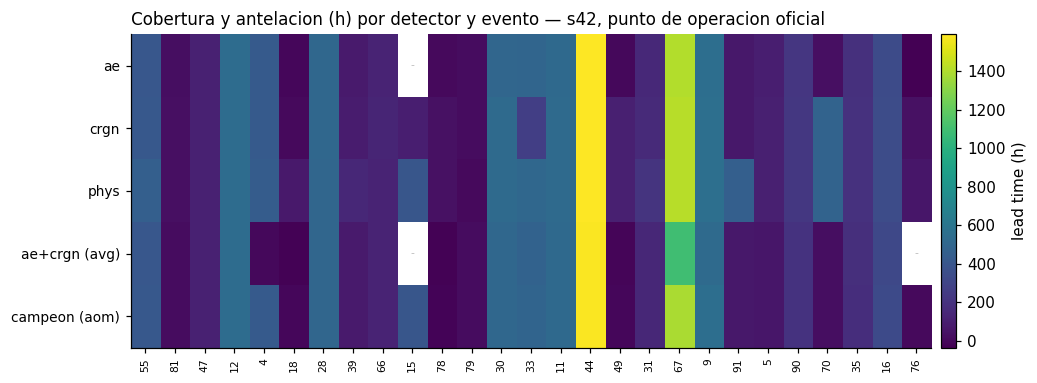

In [8]:
anoms = [e for e in eids if meta[e]["event_label"] == "anomaly"]

def leads_de(sw):
    out = {}
    h = sw["params"][1]
    for e in anoms:
        S = sw["ev_S"][e]
        lab = np.asarray(meta[e]["labels"], bool)
        idx = first_alarm(S, h)
        out[e] = None if idx is None else (meta[e]["window_timestamps"][np.flatnonzero(lab)[-1]] -
                                           meta[e]["window_timestamps"][idx]).total_seconds() / 3600.0
    return out

LEADS = {name: leads_de(sw) for name, sw in SW.items()}
mat = pd.DataFrame(LEADS).T[anoms]
xp.plot_coverage_matrix(mat, title="Cobertura y antelacion (h) por detector y evento — s42, punto de operacion oficial")
det_counts = mat.notna().sum(axis=1)
print("eventos detectados:", dict(det_counts))
resc = [e for e in anoms if LEADS["campeon (aom)"][e] is not None and LEADS["ae+crgn (avg)"][e] is None]
print(f"rescatados por el campeon respecto de AE+CRGN: {resc}")

Tres lecturas del mapa.

1. **El campeón cubre 2 eventos más que AE+CRGN**, los rescatados ev15 y ev76. Ahí está,
   literalmente, la ganancia de cobertura que phys aporta al trío.
2. **phys detecta muchísimo, 24/27**, pero ya sabemos a qué precio en *accuracy*, y el trío filtra.
3. En los eventos comunes, las antelaciones del campeón siguen de cerca a las mejores individuales,
   de modo que la fusión casi no añade retraso.

### 3.3 La antelación que la pareja pierde y el trío recupera

Un detalle del mapa merece atención. En ev4, el AE y CRGN por separado alarman con ~428 h de
antelación, pero su fusión por media (el campeón *anterior* del trabajo) se queda en **3 h**, porque
al promediar la señal temprana de un miembro se diluye con el silencio del otro en el punto de
operación conjunto. El trío con phys y el combinador AOM la **recupera**, con 428 h. En ev67 ocurre
lo mismo a otra escala, 1094 h --> 1387 h. Es la mejora del campeón vista evento a evento, porque no
solo cubre más fallos, también devuelve antelaciones que la pareja había perdido.

ev4: AE solo 429 h | AE+CRGN 3 h | campeon 428 h
ev67: AE solo 1406 h | AE+CRGN 1094 h | campeon 1387 h


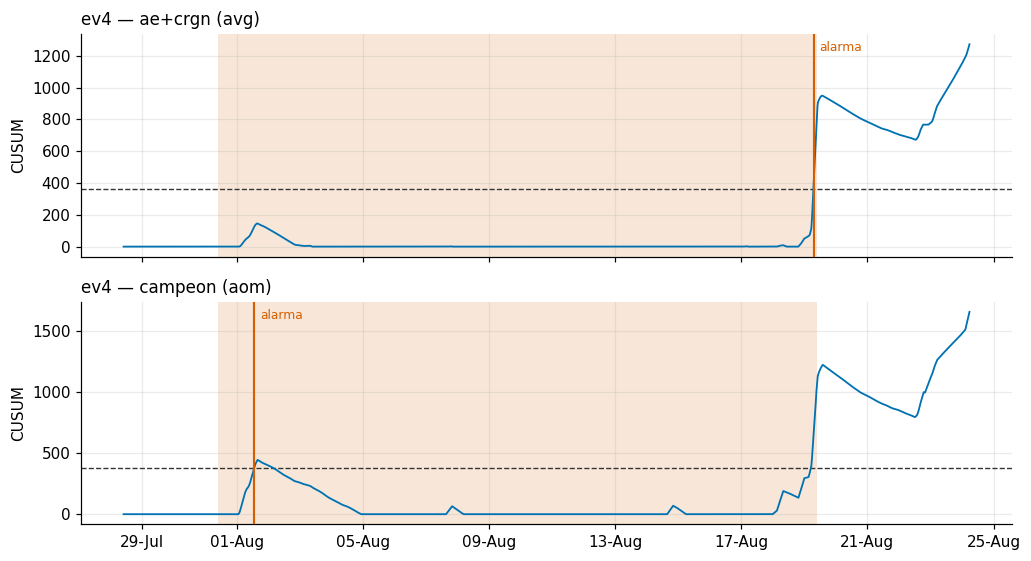

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.2), sharex=True)
e = 4
m = meta[e]
for ax, name in zip(axes, ("ae+crgn (avg)", "campeon (aom)")):
    sw = SW[name]
    xp.plot_event_timeline(m["window_timestamps"], sw["ev_S"][e], sw["params"][1], m["labels"],
                           alarm_idx=first_alarm(sw["ev_S"][e], sw["params"][1]),
                           title=f"ev{e} — {name}", ax=ax)
plt.tight_layout()
for e in (4, 67):
    print(f"ev{e}: AE solo {LEADS['ae'][e]:.0f} h | AE+CRGN {LEADS['ae+crgn (avg)'][e]:.0f} h | "
          f"campeon {LEADS['campeon (aom)'][e]:.0f} h")

## 4. ev15, el fallo que solo la física ve a tiempo

En el notebook 1, ev15 fue el caso sin precursor, donde ni el autoencoder ni TrajDev, los dos
mejores modelos *de valores* del trabajo, vieron nada (margen sobre umbral 0.1-0.2×). El mapa de
cobertura de arriba lo desmiente a medias, porque **sí había precursor, pero no en los valores de
los sensores sino en la relación entre ellos**. El score de coherencia de phys se dispara ~17 días
antes del final de la ventana, CRGN lo confirma tarde, y el campeón alarma con 402 horas.

ae               SIN alarma
crgn             alarma 104 h antes
phys             alarma 404 h antes
campeon (aom)    alarma 402 h antes


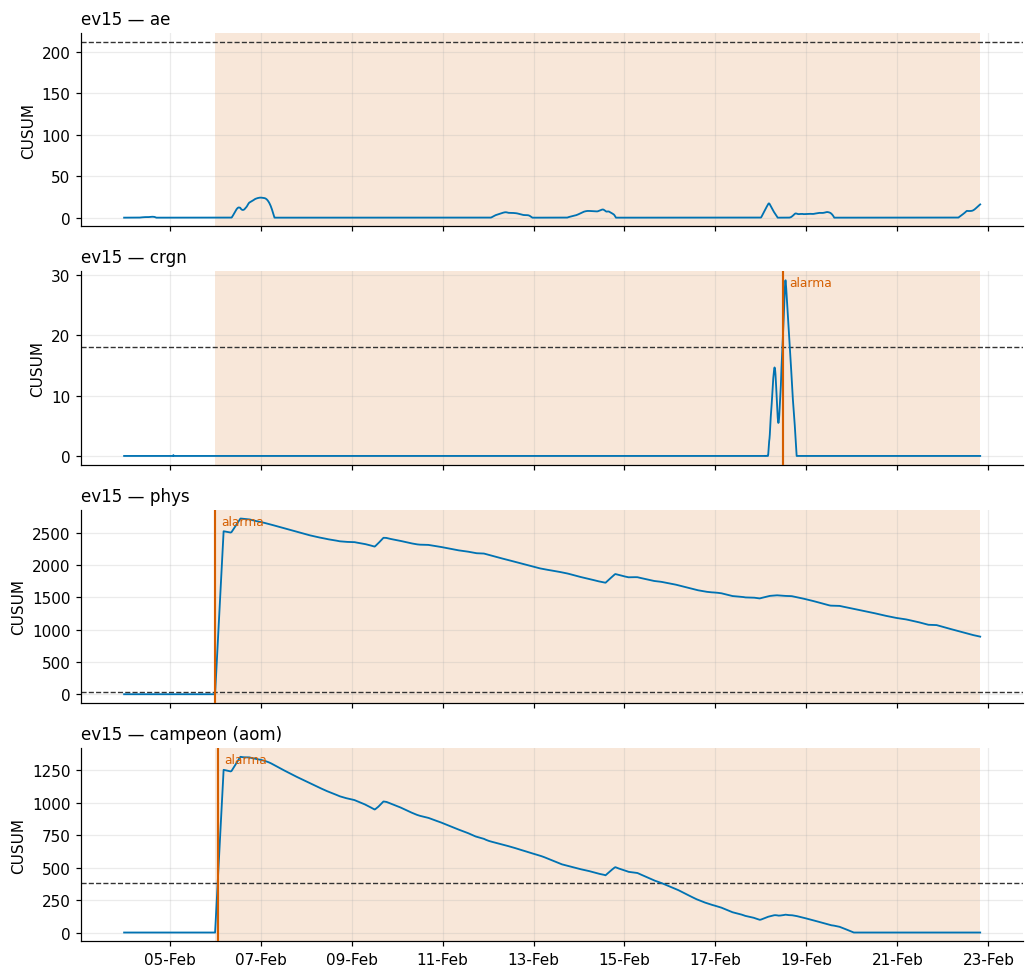

In [10]:
e = 15
m = meta[e]
fig, axes = plt.subplots(4, 1, figsize=(9.5, 9), sharex=True)
for ax, name in zip(axes, ("ae", "crgn", "phys", "campeon (aom)")):
    sw = SW[name]
    idx = first_alarm(sw["ev_S"][e], sw["params"][1])
    xp.plot_event_timeline(m["window_timestamps"], sw["ev_S"][e], sw["params"][1], m["labels"],
                           alarm_idx=idx, title=f"ev{e} — {name}", ax=ax)
plt.tight_layout()
for name in ("ae", "crgn", "phys", "campeon (aom)"):
    l = LEADS[name][e]
    print(f"{name:16} {'SIN alarma' if l is None else f'alarma {l:.0f} h antes'}")

### 4.1 La instancia física, qué par se rompe

Los canales de coherencia de las señales físicas derivadas (los mismos 9 pares de phys) permiten
bajar a la instancia. ¿Qué pareja de sensores redundantes se está separando? La figura muestra los
tres pares más activos del evento, que son la explicación física de la alarma con nombre de
sensores.

pares mas activos: ['sdp__sensor_191__sensor_192', 'sdp__sensor_106__sensor_211', 'sdp__sensor_153__sensor_186']


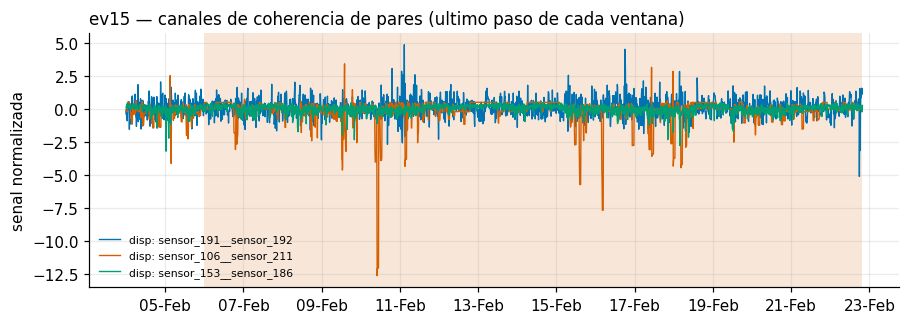

In [11]:
ev_atlas = {ev["event_id"]: ev for ev in load_trajdev_events(FARM)}
ea = ev_atlas[15]
pav_idx = [i for i, c in enumerate(b_td["ch_names"]) if c.startswith(("pav__", "sdp__"))]
act = np.array([np.abs(ea["data"][:, :, i]).mean() for i in pav_idx])
top3 = [pav_idx[i] for i in np.argsort(act)[::-1][:3]]
fig, ax = plt.subplots(figsize=(9.5, 3))
from src.xai.plots import _shade_anomaly
_shade_anomaly(ax, ea["window_timestamps"], ea["labels"])
for i in top3:
    ax.plot(ea["window_timestamps"], ea["data"][:, -1, i], lw=0.9,
            label=b_td["ch_names"][i].replace("pav__", "coh: ").replace("sdp__", "disp: "))
ax.legend(fontsize=7); ax.set_title("ev15 — canales de coherencia de pares (ultimo paso de cada ventana)", loc="left")
ax.set_ylabel("senal normalizada")
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
print("pares mas activos:", [b_td["ch_names"][i] for i in top3])

### 4.2 La instancia de la fusión en la ventana de alarma

Para la misma alarma, la vista del combinador, con los tres z de los miembros en la ventana del
disparo del campeón y el miembro dominante a lo largo del evento, es decir, cuál sostiene el máximo
en cada instante. Es la descomposición exacta de la decisión, sin aproximación.

instancia de la alarma (2023-02-06 01:30:00): z_ae = 0.4 | z_crgn = 0.2 | z_phys95maxrate = 94.1


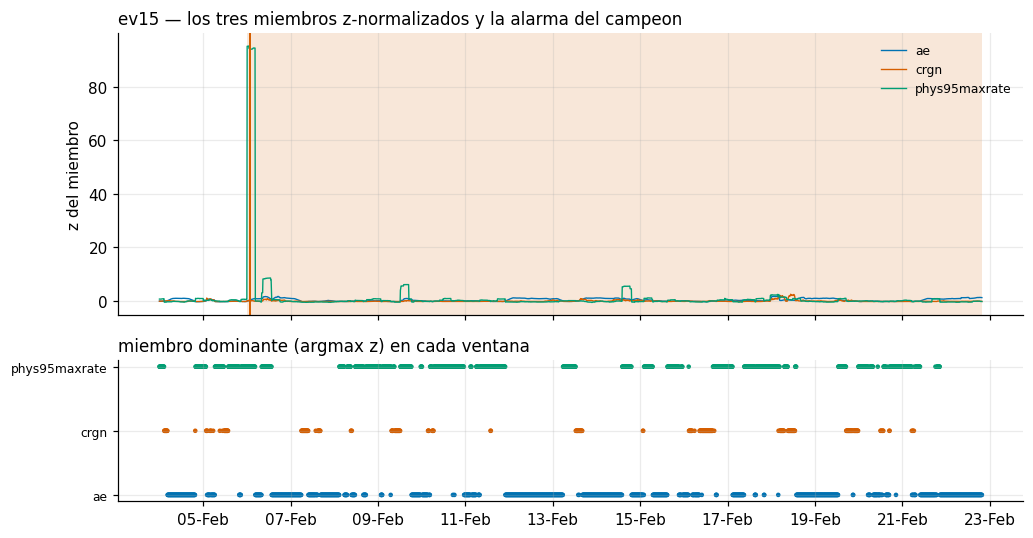

In [12]:
e = 15
trz, evz = zparts(MIEMBROS)
zs = {d: evz[d][e] for d in MIEMBROS}
sw_c = SW["campeon (aom)"]
idx = first_alarm(sw_c["ev_S"][e], sw_c["params"][1])
m = meta[e]
fig, axes = plt.subplots(2, 1, figsize=(9.5, 5), sharex=True, height_ratios=[2, 1])
_shade_anomaly(axes[0], m["window_timestamps"], m["labels"])
for i, d in enumerate(MIEMBROS):
    axes[0].plot(m["window_timestamps"], zs[d], lw=0.9, color=xp.PALETTE[i], label=d)
if idx is not None:
    axes[0].axvline(m["window_timestamps"][idx], color="#D55E00", lw=1.3)
axes[0].legend(fontsize=8); axes[0].set_ylabel("z del miembro")
axes[0].set_title("ev15 — los tres miembros z-normalizados y la alarma del campeon", loc="left")
dom = np.argmax(np.vstack([zs[d] for d in MIEMBROS]), axis=0)
axes[1].scatter(m["window_timestamps"], dom, c=[xp.PALETTE[i] for i in dom], s=4)
axes[1].set_yticks(range(3)); axes[1].set_yticklabels(MIEMBROS, fontsize=8)
axes[1].set_title("miembro dominante (argmax z) en cada ventana", loc="left")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
plt.tight_layout()
if idx is not None:
    w = {d: float(zs[d][idx]) for d in MIEMBROS}
    print(f"instancia de la alarma ({m['window_timestamps'][idx]}): " +
          " | ".join(f"z_{d} = {v:.1f}" for d, v in w.items()))

## 5. ¿Cuánto vale cada miembro? Shapley exacto sobre el CARE

Con tres jugadores, el valor de Shapley no se aproxima, se calculan las 2³ = 8 coaliciones y ya
está. La función característica es el CARE del barrido oficial de cada coalición, con protocolo
uniforme (z-scores de cada miembro, y AOM para |S| ≥ 2). El valor de Shapley de un miembro es su
aportación marginal media sobre todos los órdenes de llegada, es decir, la respuesta formal a cuánto
del 0.775 le corresponde.

In [13]:
from itertools import combinations

def _coaliciones():
    out = {}
    for r in (1, 2, 3):
        for S in combinations(MIEMBROS, r):
            tr_f, ev_f = fusionar(S, "aom" if len(S) >= 2 else "aom")
            best = h_sweep_best(tr_f, ev_f, meta, adapter)
            out["|".join(S)] = best["care"]
    return {"vals": np.array(list(out.values())), "keys": np.array(list(out.keys()))}

co = cached("coaliciones_care", _coaliciones)
V = {tuple(k.split("|")): float(v) for k, v in zip(co["keys"], co["vals"])}
V[()] = 0.0
import math
phi = {}
n = len(MIEMBROS)
for i in MIEMBROS:
    s = 0.0
    resto = [d for d in MIEMBROS if d != i]
    for r in range(len(resto) + 1):
        for S in combinations(resto, r):
            w = math.factorial(len(S)) * math.factorial(n - len(S) - 1) / math.factorial(n)
            s += w * (V[tuple(sorted(S + (i,)))] - V[tuple(sorted(S))])
    phi[i] = s
V = {tuple(sorted(k)) if isinstance(k, tuple) else k: v for k, v in V.items()}
print("CARE test-tuned (s42) por coalicion:")
for k in sorted(V, key=len):
    if k: print(f"   {{{', '.join(k)}}}: {V[k]:.4f}")
print("\nvalores de Shapley (suman el CARE del trio):")
for d, v in phi.items():
    print(f"   phi_{d} = {v:.4f}  ({100*v/sum(phi.values()):.0f}%)")
print(f"\naporte marginal de phys SOBRE ae+crgn (aom): "
      f"{V[tuple(sorted(('ae','crgn','phys95maxrate')))] - V[tuple(sorted(('ae','crgn')))]:+.4f}")

CARE test-tuned (s42) por coalicion:
   {ae}: 0.7432
   {crgn}: 0.7381
   {phys95maxrate}: 0.6683
   {ae, crgn}: 0.7552
   {ae, phys95maxrate}: 0.7666
   {crgn, phys95maxrate}: 0.7039
   {ae, crgn, phys95maxrate}: 0.7750

valores de Shapley (suman el CARE del trio):
   phi_ae = 0.2907  (38%)
   phi_crgn = 0.2567  (33%)
   phi_phys95maxrate = 0.2276  (29%)

aporte marginal de phys SOBRE ae+crgn (aom): +0.0198


Text(0.0, 1.0, 'Waterfall de Shapley: cuanto CARE aporta cada miembro')

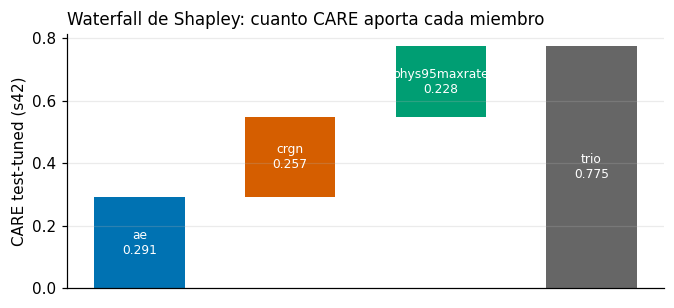

In [14]:
fig, ax = plt.subplots(figsize=(7, 3))
names = list(phi.keys())
vals = [phi[d] for d in names]
cum = np.concatenate([[0], np.cumsum(vals)])
for i, (d, v) in enumerate(zip(names, vals)):
    ax.bar(i, v, bottom=cum[i], color=xp.PALETTE[i], width=0.6)
    ax.text(i, cum[i] + v / 2, f"{d}\n{v:.3f}", ha="center", va="center", fontsize=8, color="white")
ax.bar(len(names), cum[-1], color="#666666", width=0.6)
ax.text(len(names), cum[-1] / 2, f"trio\n{cum[-1]:.3f}", ha="center", va="center", fontsize=8, color="white")
ax.set_xticks([]); ax.set_ylabel("CARE test-tuned (s42)")
ax.set_title("Waterfall de Shapley: cuanto CARE aporta cada miembro", loc="left")

Tres números del reparto.

1. **phys vale el 29% del campeón (φ = 0.228) siendo el peor detector en solitario (0.668).** Es la
   cuantificación de la lección del trabajo, porque el valor de un miembro no es su CARE individual
   sino lo que añade a las coaliciones, es decir, cobertura y antelación que los otros no tienen.
2. **Su aportación marginal sobre la pareja AE+CRGN es +0.020** (0.755 --> 0.775 en esta semilla, y
   +0.024 en la media multi-semilla versionada, 5/5). Es el salto que convirtió al campeón.
3. La coalición {AE, phys} ya rinde 0.767 en esta semilla, de modo que CRGN aporta un margen fino
   aquí (+0.008), pero su φ global (33%) refleja que sostiene a *todas* las coaliciones en las que
   entra. La selección del trío se decidió con el protocolo multi-semilla completo de la campaña, no
   con esta descomposición ilustrativa.

## 6. Dónde la fusión empeora

Ninguna fusión es gratis. El mapa del apartado 3.2 también contiene los casos donde el trío llega
*más tarde* que el mejor miembro, típicamente cuando phys añade ruido en un evento donde el AE ya
era certero y el punto de operación conjunto es más conservador. Los cuantificamos sobre los eventos
donde el campeón pierde más de 12 h respecto del AE solo.

In [15]:
def balance_vs(base):
    peores = {e: (LEADS[base][e], LEADS["campeon (aom)"][e]) for e in anoms
              if LEADS[base][e] is not None and LEADS["campeon (aom)"][e] is not None
              and LEADS[base][e] - LEADS["campeon (aom)"][e] > 12}
    resc = [e for e in anoms if LEADS[base][e] is None and LEADS["campeon (aom)"][e] is not None]
    gana = {e: (LEADS[base][e], LEADS["campeon (aom)"][e]) for e in anoms
            if LEADS[base][e] is not None and LEADS["campeon (aom)"][e] is not None
            and LEADS["campeon (aom)"][e] - LEADS[base][e] > 12}
    print(f"— vs {base}: rescatados {resc} | adelanta>12h en {sorted(gana)} | retrasa>12h en:")
    for e, (a, c) in peores.items():
        print(f"     ev{e}: {a:.0f} h -> {c:.0f} h ({c-a:+.0f})")

balance_vs("ae+crgn (avg)")   # la referencia que el campeon batio 5/5
balance_vs("ae")              # y el baseline original, por honestidad
print("\nEl neto formal es el pareado multi-semilla committeado: campeon 0.7694 vs AE+CRGN "
      "0.7452 (5/5) y vs AE 0.7206.")

— vs ae+crgn (avg): rescatados [15, 76] | adelanta>12h en [4, 9, 16, 18, 33, 67] | retrasa>12h en:
— vs ae: rescatados [15] | adelanta>12h en [76] | retrasa>12h en:
     ev78: 6 h -> -16 h (-22)
     ev67: 1406 h -> 1387 h (-18)
     ev5: 102 h -> 65 h (-36)
     ev90: 224 h -> 205 h (-19)

El neto formal es el pareado multi-semilla committeado: campeon 0.7694 vs AE+CRGN 0.7452 (5/5) y vs AE 0.7206.


## 7. Por qué la reconstrucción no ve ev15

Cerramos con la atribución del AE, es decir, el residuo por sensor devuelto al espacio físico con la
inversa del mapa PCA, el *contribution plot* clásico, sobre el evento rescatado. Si la tesis del
apartado 4 es correcta, el residuo del AE debería estar **plano** en ev15. No es que el AE falle, es
que el estado de cada sensor siguió siendo reconstruible, y lo que se rompió fue la *relación* del
par, invisible para un score de error medio de reconstrucción.

z maximo del residuo AE en tramo anomalo: ev15 = 0.7 vs ev11 = 12.4


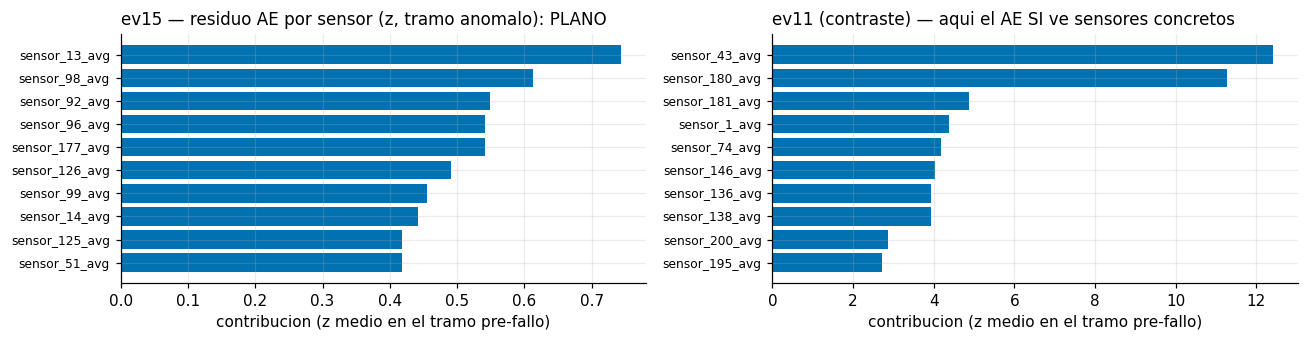

In [16]:
ae_b = load_ae(FARM)
aevs = {x["event_id"]: x for x in load_ae_events(FARM)}

def _res15():
    a15 = aevs[15]
    res = ae_residual_sensor(ae_b, a15["raw"])
    lab = np.asarray(meta[15]["labels"], bool)
    normal = res[~lab] if (~lab).any() else res[:300]
    mu_r, sd_r = residual_train_stats(normal)
    z11 = None
    return {"zres": (res - mu_r) / sd_r}

zres15 = cached("ae_res_ev15", _res15)["zres"]
m = meta[15]
lab = np.asarray(m["labels"], bool)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
xp.plot_sensor_ranking(zres15[lab].mean(axis=0), ae_b["feats"], top=10, ax=axes[0],
                       title="ev15 — residuo AE por sensor (z, tramo anomalo): PLANO")
def _res11():
    a11 = aevs[11]
    res = ae_residual_sensor(ae_b, a11["raw"])
    lab11 = np.asarray(meta[11]["labels"], bool)
    normal = res[~lab11] if (~lab11).any() else res[:300]
    mu_r, sd_r = residual_train_stats(normal)
    return {"zres": (res - mu_r) / sd_r}

zres11 = cached("ae_res_ev11", _res11)["zres"]
lab11 = np.asarray(meta[11]["labels"], bool)
xp.plot_sensor_ranking(zres11[lab11].mean(axis=0), ae_b["feats"], top=10, ax=axes[1],
                       title="ev11 (contraste) — aqui el AE SI ve sensores concretos")
plt.tight_layout()
print(f"z maximo del residuo AE en tramo anomalo: ev15 = {zres15[lab].mean(axis=0).max():.1f} "
      f"vs ev11 = {zres11[lab11].mean(axis=0).max():.1f}")

## 8. Conclusiones y limitaciones

1. **La ganancia del campeón se puede señalar evento a evento.** Dos rescatados (ev15, ev76) y
   antelaciones preservadas donde la media las diluía (ev4, ev67), es decir, cobertura nueva. El
   Shapley exacto pone número al reparto y a la aportación marginal de phys sobre la pareja.
2. **El reparto de papeles es real y medible.** AE aporta *accuracy*, CRGN cobertura con precisión,
   y phys cobertura y anticipación, con unos falsos positivos que absorbe el trío.
3. **La explicación llega hasta la física.** La alarma de ev15 se rastrea hasta pares concretos de
   sensores redundantes separándose, mientras el residuo por sensor del AE permanece plano, lo que
   demuestra que reconstrucción y coherencia son mecanismos distintos.
4. **El coste está a la vista.** Algunos eventos llegan algo más tarde que con el AE solo, y el neto, que gana en las cinco semillas, es claramente positivo.

**Limitaciones.**

1. CRGN se explica aquí a nivel de score, porque su interpretabilidad interna, las representaciones
   contrastivas de grafo, queda fuera del alcance. Es el miembro menos transparente del trío.
2. Los análisis por evento usan, para dibujar, el punto de operación que da el mejor CARE del
   barrido, es decir, el umbral elegido con las etiquetas a la vista. Las decisiones del trabajo son
   CARE-CV multi-semilla.
3. La campaña demostró que este trío está **estructuralmente saturado**, porque nueve
   configuraciones retadoras (cuartos miembros, uniones, comités) no lo mejoraron. La métrica premia
   una familia calibrada con cobertura y no la suma indiscriminada de señales.

## Referencias

- Gück, C., Roelofs, C. M. A., Faulstich, S. (2024). *CARE to Compare: A Real-World Benchmark
  Dataset for Early Fault Detection in Wind Turbine Data.* Data, 9(12), 138.
- Takeishi, N., Kawahara, Y. (2023). *A Characteristic Function for Shapley-Value-Based Attribution
  of Anomaly Scores.* Transactions on Machine Learning Research.
- Levy, E., et al. (2026). *Analyzing SHAP to Understand Anomaly Detection Algorithm Behaviors and
  Their Complementarity.* IDA 2026. La divergencia de explicaciones predice complementariedad.
- Roelofs, C. M. A., Lutz, M.-A., Faulstich, S., Vogt, S. (2021). *Autoencoder-based anomaly root
  cause analysis for wind turbines* (ARCANA). Energy and AI, 4, 100065.
- Alcalá, C. F., Qin, S. J. (2009). *Reconstruction-based contribution for process monitoring.*
  Automatica, 45(7).
- Aggarwal, C. C., Sathe, S. (2017). *Outlier Ensembles: An Introduction.* Springer. La cobertura
  complementaria como criterio de combinación.